# Screening of public goat assemblies
How complete are the centromeres in public *Capra hircus* assemblies?

The reference of the project is T2T-goat2.0 (notebook 01), whose authors resolved all the centromeres. Here the same centromere method is run on 20 candidate public assemblies, to see which ones resolve the centromeric satellite blocks well enough to be compared with it.

The assemblies were chosen from the 70 *Capra hircus* genomes in NCBI (October 2026): chromosome level, high contig N50, and not from the same animal as T2T-goat2.0. They come from several breeds and several institutions.

For each assembly the notebook does the following:
1. Downloads the genome and checks its MD5.
2. Matches every chromosome to its counterpart in T2T-goat2.0.
3. Annotates the first and last 15 Mb of each chromosome with the SatI–III units of T2T-goat2.0 and decides which end carries the centromere.
4. Delimits the centromeric block and flags blocks with gaps or little satellite.
5. Annotates the unplaced scaffolds, because satellite that did not make it into a chromosome is invisible otherwise.
6. Runs SRF again, to see whether the assembly has satellite units that T2T-goat2.0 does not have.

This notebook needs notebook 01 to have run first, because it uses the SatI–III units and the T2T-goat2.0 sequence that 01 produces. The assemblies are processed one at a time. Big files are deleted after each one, and only small tables are kept in `data/per_assembly/`. If the notebook stops it resumes where it was. The tables in `data/screening/per_assembly/` come from the complete run, which took about two hours. When they are in place the notebook skips those assemblies, so the stored outputs show them as already done.

The result is a screen: it decides which assemblies can be used for the statistics of notebook 03.

In [1]:
import os, re, gzip, hashlib, subprocess, shutil, json, io, time, shlex, traceback
import urllib.request
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyfaidx import Fasta
from Bio import SeqIO
from Bio.Seq import Seq

BASE = Path.cwd()
if BASE.name == 'notebooks': BASE = BASE.parent
DATA, TOOLS = BASE/'data', BASE/'tools'
WORK = BASE/'work'/'screening'                                   # temporary files of this notebook
RAW, FIG, SCR = DATA/'raw_ncbi', DATA/'figures', DATA/'screening'; PER = SCR/'per_assembly'
# reference files, all produced by notebook 01
T2T_FA, MMI = BASE/'work'/'clean'/'T2T.fa', WORK/'T2T.asm20.mmi'
SRF_UNITS, UNITS_CSV, MASTER = DATA/'srf.fa', DATA/'srf_units.csv', DATA/'centromeres_master.csv'
for d in (DATA, WORK, RAW, FIG, SCR, PER): d.mkdir(parents=True, exist_ok=True)
Q = lambda p: shlex.quote(str(p))
THREADS = os.cpu_count() or 2
WINDOW_MB, MAX_GAP, MIN_SAT_FRAC, SRF_WINDOW, MIN_SCAFFOLD = 15, 500_000, 0.30, 10_000_000, 20_000_000   # the first four as in notebook 01
W = WINDOW_MB*1_000_000
KINDS_SAT = ['SatI', 'SatII', 'SatIII']

ASSEMBLIES = {   # label -> accession
    'KikoP': 'GCA_057428595.1', 'SaanenM': 'GCA_057428545.1', 'KoreanBG': 'GCA_059055625.1',
    'Tib1': 'GCA_046464075.1', 'Tib2': 'GCA_049004455.1', 'Tib3': 'GCA_049004405.1', 'Hain1': 'GCA_047671635.1', 'Hain2': 'GCA_048594055.1',
    'IMAU': 'GCA_040822015.1', 'Shanbei': 'GCA_044509215.1', 'Kor2': 'GCA_059055555.1', 'Kor3': 'GCA_057557635.1', 'Kor4': 'GCA_057556445.1',
    'Guan': 'GCA_044588015.1', 'Nubi': 'GCA_044587935.1', 'Alp': 'GCA_044587945.1', 'Shan1': 'GCA_049004675.1', 'Shan2': 'GCA_049004595.1',
    'SEQ': 'GCA_984506535.1', 'ARS': 'GCA_001704415.2'}

ONLY = os.environ.get('CAPRA_ONLY')                               # e.g. CAPRA_ONLY=KikoP to test with a single assembly
if ONLY: ASSEMBLIES = {k: v for k, v in ASSEMBLIES.items() if k in ONLY.split(',')}

KMC, KMC_DUMP = TOOLS/'bin'/'kmc', TOOLS/'bin'/'kmc_dump'
SRF, SRFUTILS, K8 = TOOLS/'srf'/'srf', TOOLS/'srf'/'srfutils.js', TOOLS/'k8'
for p in (KMC, KMC_DUMP, SRF, SRFUTILS, K8, T2T_FA, SRF_UNITS, UNITS_CSV, MASTER):
    assert Path(p).exists(), f'missing {p}'
for t in ('minimap2', 'samtools'): assert shutil.which(t), t

def urlopen_retry(url, tries=6):
    for k in range(tries):
        try: return urllib.request.urlopen(url, timeout=60)
        except Exception:
            if k == tries-1: raise
            time.sleep(10*(k+1))
def run_bash(s): subprocess.run(['bash', '-o', 'pipefail', '-c', s], check=True)

# T2T-goat2.0 index (built once) and the SatI-III units with their classification
if not (MMI).exists(): run_bash(f"minimap2 -x asm20 -t {THREADS} -d {Q(MMI)} {Q(T2T_FA)} 2>/dev/null")
run_bash(f"{Q(K8)} {Q(SRFUTILS)} enlong {Q(SRF_UNITS)} > {Q(WORK/'units_long.fa')}")
units_T2T = pd.read_csv(UNITS_CSV); cls_of = units_T2T.set_index('id').family.to_dict()
T2T = pd.read_csv(MASTER); T2T = T2T[T2T.hap == 'T2T'].set_index('chr')
CI = {'SatI': 0, 'SatII': 1, 'SatIII': 2, 'other': 3}; CN = {v: k for k, v in CI.items()}; BINA = 100
print(len(ASSEMBLIES), 'assemblies |', 'Project:', BASE)

20 assemblies | Project: <repo>


In [2]:
def report(acc, what):
    rows, token = [], None
    while True:
        u = f'https://api.ncbi.nlm.nih.gov/datasets/v2/genome/accession/{acc}/{what}?page_size=1000' + (f'&page_token={token}' if token else '')
        d = json.load(urlopen_retry(u)); rows += d['reports']; token = d.get('next_page_token')
        if not token or what == 'dataset_report': return rows

def md5_file(p, chunk=1<<24):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        while b := f.read(chunk): h.update(b)
    return h.hexdigest()

def download(label, acc):
    n = acc.split('_')[1].split('.')[0]
    base = f'https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/{n[:3]}/{n[3:6]}/{n[6:9]}/'
    name = re.search(rf'href="({re.escape(acc)}_[^/"]+)/"', urlopen_retry(base).read().decode()).group(1); base += name + '/'
    md5s = {l.split()[1].lstrip('./'): l.split()[0] for l in urlopen_retry(base + 'md5checksums.txt').read().decode().splitlines() if l.strip()}
    fn = f'{name}_genomic.fna.gz'; gz = RAW/fn
    if not (gz.exists() and md5_file(gz) == md5s[fn]): subprocess.run(['curl', '-sS', '-L', '--retry', '5', '-C', '-', '-o', str(gz), base + fn], check=True)
    got = md5_file(gz); assert got == md5s[fn], 'MD5 mismatch'
    return gz, got

def norm_name(n):
    m = re.fullmatch(r'(?:chr)?(\d+|X)', str(n), re.I)
    return 'CHI' + m.group(1).upper() if m else None

def chrom_table(label, acc):
    df = pd.DataFrame([dict(accession=r['genbank_accession'], ncbi_name=r.get('chr_name'), role=r.get('role'), length=r['length']) for r in report(acc, 'sequence_reports')])
    df['isY'] = df.ncbi_name.astype(str).str.upper().eq('Y'); df['isMT'] = df.ncbi_name.astype(str).str.upper().isin(['MT', 'M'])
    placed = df.role.eq('assembled-molecule') & ~df.isY & ~df.isMT
    if placed.sum() == 0: placed = (df.length >= MIN_SCAFFOLD) & ~df.isY            # scaffold-level assemblies: long sequences stand for chromosomes
    df['placed'] = placed; df['chr'] = [norm_name(n) if p else None for n, p in zip(df.ncbi_name, df.placed)]
    used, k = set(), 0
    for i in df.index[df.placed]:
        n = df.at[i, 'chr']
        if n is None or n in used: k += 1; n = f'seq{k}'
        df.at[i, 'chr'] = n; used.add(n)
    df['kind'] = [None if c is None else ('X' if c == 'CHIX' else 'autosome') for c in df.chr]
    df['seqname'] = [f'{label}_{c}' if p else f'{label}_unplaced_{a}' for c, p, a in zip(df.chr, df.placed, df.accession)]
    df.insert(0, 'hap', label); return df

def rename_fasta(label, gz, df):
    out = WORK/f'{label}.fa'; mp = df.set_index('accession').seqname.to_dict()
    with gzip.open(gz, 'rt') as fi, open(out, 'w') as fo:
        for line in fi:
            if line.startswith('>'): a = line[1:].split()[0]; fo.write(f'>{mp.get(a, label + "_other_" + a)}\n')
            else: fo.write(line.upper())
    subprocess.run(['samtools', 'faidx', str(out)], check=True); return out

def chrom_map(label, fa_path, df):
    fa = Fasta(str(fa_path), as_raw=True, sequence_always_upper=True); seg = 300_000; sub = df[df.placed]
    mid = WORK/f'{label}.mid.fa'
    with open(mid, 'w') as fo:
        for r in sub.itertuples():
            s = max(0, r.length//2 - seg//2); fo.write(f'>{r.seqname}\n{fa[r.seqname][s:s+seg]}\n')
    paf = subprocess.check_output(f"minimap2 -t {THREADS} --secondary=no {Q(MMI)} {Q(mid)} 2>/dev/null", shell=True, text=True)
    out = []
    if paf.strip():
        d = pd.read_csv(io.StringIO(paf), sep='\t', header=None, usecols=[0, 5, 9], names=['q', 't', 'nm'])
        best = d.groupby(['q', 't']).nm.sum().reset_index().sort_values('nm', ascending=False).drop_duplicates('q').set_index('q')
    else: best = pd.DataFrame(columns=['t', 'nm'])
    for r in sub.itertuples():
        t = best.t.get(r.seqname); out.append(dict(hap=label, chr=r.chr, T2T_match=None if t is None else t.split('_', 1)[1], matched_bp=int(best.nm.get(r.seqname, 0))))
    m = pd.DataFrame(out); m['same_number'] = m.chr == m.T2T_match; return m

def annotate(fa_path, tag):
    paf = WORK/f'{tag}.paf'; t0 = time.time()
    run_bash(f"minimap2 -N 1000000 -f 1000 -r 100,100 -t {THREADS} {Q(WORK/'units_long.fa')} {Q(fa_path)} > {Q(paf)} 2>/dev/null")
    df = pd.read_csv(paf, sep='\t', header=None, usecols=[0, 1, 2, 3, 5, 9, 10], names=['q', 'ql', 'qs', 'qe', 't', 'nm', 'bl'])
    df['ci'] = df.t.map(cls_of).fillna('other').map(CI); df['idn'] = df.nm/df.bl
    df = df.sort_values('idn', ascending=False); rows = []
    for q, g in df.groupby('q'):
        arr = np.full(int(g.ql.iloc[0]//BINA) + 1, -1, np.int8)
        for s_, e_, c_ in zip((g.qs//BINA).to_numpy(), ((g.qe-1)//BINA + 1).to_numpy(), g.ci.to_numpy()):
            seg = arr[s_:e_]; seg[seg < 0] = c_
        cut = np.flatnonzero(np.diff(np.r_[-2, arr, -2]))
        for a_, b_ in zip(cut[:-1], cut[1:]):
            if arr[a_] >= 0: rows.append(dict(seq=q, start=int(a_*BINA), end=int(b_*BINA), family=CN[int(arr[a_])], bp=int((b_-a_)*BINA)))
    return pd.DataFrame(rows, columns=['seq', 'start', 'end', 'family', 'bp'])

def gap_runs(seq): return [(m.start(), m.end()) for m in re.finditer(r'N+', seq)]

def end_windows(label, fa_path, df):
    fa = Fasta(str(fa_path), as_raw=True, sequence_always_upper=True); ends, gaps = [], []
    fl, fr = WORK/f'{label}.left.fa', WORK/f'{label}.right.fa'
    with open(fl, 'w') as a_, open(fr, 'w') as b_:
        for r in df[df.placed].itertuples():
            w = min(W, r.length); L, R = fa[r.seqname][0:w], fa[r.seqname][r.length-w:r.length]
            a_.write(f'>{r.seqname}|L\n{L}\n'); b_.write(f'>{r.seqname}|R\n{R}\n')
            for win, s in (('L', L), ('R', R)):
                for x, y in gap_runs(s): gaps.append(dict(hap=label, chr=r.chr, win=win, wlen=w, start=x, end=y))
    for win, f in (('L', fl), ('R', fr)):
        a = annotate(f, f'{label}.{win}'); a['win'] = win; a['hap'] = label
        a['chr'] = a.seq.str.split('|').str[0].str.split('_', n=1).str[1]; ends.append(a.drop(columns='seq'))
    return pd.concat(ends, ignore_index=True), pd.DataFrame(gaps, columns=['hap', 'chr', 'win', 'wlen', 'start', 'end'])

def orientation(label, df, ends):
    sat = ends[ends.family.isin(KINDS_SAT)]
    tot = sat.groupby(['hap', 'chr', 'win']).bp.sum().unstack(fill_value=0).div(1e6).reset_index()
    for c in ('L', 'R'):
        if c not in tot: tot[c] = 0.0
    tot = tot.rename(columns={'L': 'sat_left_Mb', 'R': 'sat_right_Mb'})
    tot = df[df.placed][['hap', 'chr', 'length', 'kind']].merge(tot, on=['hap', 'chr'], how='left').fillna({'sat_left_Mb': 0, 'sat_right_Mb': 0})
    tot['side'] = np.where(tot.sat_left_Mb >= tot.sat_right_Mb, 'L', 'R'); return tot

def orient_df(d, side_of, length_of):
    d = d.copy(); d['side'] = [side_of[(h, c)] for h, c in zip(d.hap, d.chr)]; d = d[d.win == d.side].copy()
    if 'wlen' not in d: d['wlen'] = [min(W, int(length_of[(h, c)])) for h, c in zip(d.hap, d.chr)]
    r = d.side == 'R'; s0, e0 = d.start.copy(), d.end.copy()
    d.loc[r, 'start'] = d.wlen[r] - e0[r]; d.loc[r, 'end'] = d.wlen[r] - s0[r]; return d

def centromere_block(a):
    a = a.sort_values('start'); blocks, cur = [], None
    for r in a.itertuples():
        if cur is None: cur = [r.start, r.end, r.bp]
        elif r.start - cur[1] <= MAX_GAP: cur[1] = max(cur[1], r.end); cur[2] += r.bp
        else: blocks.append(cur); cur = [r.start, r.end, r.bp]
    blocks.append(cur); b = max(blocks, key=lambda x: x[2]); return int(b[0]), int(b[1])

def centromeres(label, df, ends, gaps, tot, chrmap):
    side_of = {(r.hap, r.chr): r.side for r in tot.itertuples()}; length_of = {(r.hap, r.chr): r.length for r in df[df.placed].itertuples()}
    ann_o = orient_df(ends[ends.family.isin(KINDS_SAT)], side_of, length_of); gaps_o = orient_df(gaps, side_of, length_of) if len(gaps) else gaps
    rows = []
    for r in df[df.placed].itertuples():
        a = ann_o[(ann_o.hap == r.hap) & (ann_o.chr == r.chr)]; d = dict(hap=r.hap, chr=r.chr, kind=r.kind, length=r.length, side=side_of[(r.hap, r.chr)])
        if a.empty: rows.append(d); continue
        s, e = centromere_block(a); inside = a[(a.start >= s) & (a.end <= e)]
        d.update(cen_start=s, cen_end=e, cen_len=e - s); d.update({k: int(inside[inside.family == k].bp.sum()) for k in KINDS_SAT})
        g = gaps_o[(gaps_o.hap == r.hap) & (gaps_o.chr == r.chr)] if len(gaps_o) else gaps_o
        d['n_gaps_cen'] = int(((g.start < e + 100_000) & (g.end > max(0, s - 100_000))).sum()) if len(g) else 0; rows.append(d)
    c = pd.DataFrame(rows)
    for k in ('n_gaps_cen', 'cen_len'):
        if k not in c: c[k] = np.nan
    c['sat_bp'] = c[KINDS_SAT].sum(axis=1); c['sat_frac'] = c.sat_bp/c.cen_len
    c['detected'] = c.cen_len.notna() & (c.cen_len >= 250_000); c['complete'] = c.detected & c.n_gaps_cen.eq(0); c['low_satellite'] = c.sat_frac < MIN_SAT_FRAC
    c['T2T_chr'] = c.merge(chrmap[['hap', 'chr', 'T2T_match']], on=['hap', 'chr'], how='left').T2T_match.values
    c['len_vs_T2T'] = c.length.values/T2T.length.reindex(c.T2T_chr).values
    c['cen_vs_T2T'] = c.cen_len.values/T2T.cen_len.reindex(c.T2T_chr).values; c['sat_vs_T2T'] = c.sat_bp.values/T2T.sat_bp.reindex(c.T2T_chr).values
    return c

def unplaced_satellite(label, fa_path, df):
    names = df[~df.placed & ~df.isY].seqname.tolist()
    if not names: return dict(hap=label, unplaced_sequences=0, unplaced_Mb=0.0, SatI_Mb=0.0, SatII_Mb=0.0, SatIII_Mb=0.0)
    fa = Fasta(str(fa_path), as_raw=True, sequence_always_upper=True); f = WORK/f'{label}.unplaced.fa'
    with open(f, 'w') as fo:
        for n in names: fo.write(f'>{n}\n{fa[n][:]}\n')
    a = annotate(f, f'{label}.unplaced'); a = a[a.family.isin(KINDS_SAT)]; t = a.groupby('family').bp.sum()
    return dict(hap=label, unplaced_sequences=len(names), unplaced_Mb=round(df[~df.placed & ~df.isY].length.sum()/1e6, 2), **{k + '_Mb': round(t.get(k, 0)/1e6, 2) for k in KINDS_SAT})

CORE = 'AATCACGTGGGCCCC'; CORE_RC = str(Seq(CORE).reverse_complement())
def classify_unit(seq):
    s = str(seq).upper(); L = len(s)
    if L >= 22 and min(1, 22*(s.count(CORE) + s.count(CORE_RC))/L) >= 0.6: return 'SatIII'
    for n in range(1, 7):
        if abs(L - 816*n) <= 0.04*816*n: return 'SatI'
    for n in range(1, 7):
        if abs(L - 702*n) <= 0.04*702*n: return 'SatII'
    return 'other'

REFK = None
def ref_kmers(k=15):
    global REFK
    if REFK is None:
        REFK = set()
        for r in SeqIO.parse(SRF_UNITS, 'fasta'):
            s = str(r.seq).upper(); rc = str(Seq(s).reverse_complement())
            for t in (s, rc): REFK.update(t[i:i+k] for i in range(len(t) - k + 1))
    return REFK

def srf_units(label, fa_path, df, tot):
    D = WORK/f'{label}_srf'; D.mkdir(exist_ok=True); fa = Fasta(str(fa_path), as_raw=True, sequence_always_upper=True)
    side_of = {(r.hap, r.chr): r.side for r in tot.itertuples()}
    with open(D/'prox.fa', 'w') as fo:
        for r in df[df.placed].itertuples():
            w = min(W, r.length); s = fa[r.seqname][0:min(SRF_WINDOW, w)] if side_of[(label, r.chr)] == 'L' else str(Seq(fa[r.seqname][r.length-w:r.length]).reverse_complement())[0:min(SRF_WINDOW, w)]
            fo.write(f'>{r.chr}\n{s}\n')
    run_bash(f"cd {Q(D)}; rm -rf tmp_dir count.kmc*; mkdir -p tmp_dir; {Q(KMC)} -fm -k151 -t{min(THREADS, 8)} -m12 -sm -ci20 -cs1000000 prox.fa count.kmc tmp_dir > /dev/null; {Q(KMC_DUMP)} count.kmc count.txt; {Q(SRF)} -p {label} count.txt > srf.fa")
    rk, k, out = ref_kmers(), 15, []
    for rec in SeqIO.parse(D/'srf.fa', 'fasta'):
        s = str(rec.seq).upper(); n = len(s) - k + 1
        share = sum(1 for i in range(max(n, 0)) if s[i:i+k] in rk)/max(n, 1) if n > 0 else 0.0
        out.append(dict(hap=label, id=rec.id, length=len(s), family=classify_unit(s), kmer_share_in_T2T=round(share, 2)))
    return pd.DataFrame(out, columns=['hap', 'id', 'length', 'family', 'kmer_share_in_T2T'])

In [3]:
def process(label, acc):
    out = PER/label; out.mkdir(exist_ok=True); t0 = time.time()
    meta = report(acc, 'dataset_report')[0]; ai = meta['assembly_info']; st = meta['assembly_stats']
    attrs = {a['name']: a['value'] for a in ai.get('biosample', {}).get('attributes', [])}
    pd.DataFrame([dict(label=label, accession=acc, name=ai.get('assembly_name'), level=ai.get('assembly_level'), breed=attrs.get('breed') or ai.get('biosample', {}).get('description', {}).get('title'),
                       sex=attrs.get('sex', ''), institution=ai.get('biosample', {}).get('owner', {}).get('name', ''), tech=ai.get('sequencing_tech', ''),
                       contig_n50_Mb=round(int(st.get('contig_n50', 0))/1e6, 1), sequences=st.get('number_of_component_sequences'), total_Gb=round(int(st['total_sequence_length'])/1e9, 2))]).to_csv(out/'meta.csv', index=False)
    gz, md5 = download(label, acc); df = chrom_table(label, acc); df.to_csv(out/'sequences.csv', index=False)
    fa_path = rename_fasta(label, gz, df); cm = chrom_map(label, fa_path, df); cm.to_csv(out/'chrom_map.csv', index=False)
    ends, gaps = end_windows(label, fa_path, df); ends.to_csv(out/'annotation_ends.csv', index=False)
    tot = orientation(label, df, ends); tot.to_csv(out/'orientation.csv', index=False)
    c = centromeres(label, df, ends, gaps, tot, cm); c.to_csv(out/'centromeres.csv', index=False)
    pd.DataFrame([unplaced_satellite(label, fa_path, df)]).to_csv(out/'unplaced.csv', index=False)
    srf_units(label, fa_path, df, tot).to_csv(out/'srf_units.csv', index=False)
    (out/'status.json').write_text(json.dumps(dict(status='done', md5=md5, minutes=round((time.time() - t0)/60, 1))))
    for p in WORK.glob(f'{label}*'): shutil.rmtree(p) if p.is_dir() else p.unlink()      # keep only the small tables
    gz.unlink(missing_ok=True)

for label, acc in ASSEMBLIES.items():
    st = PER/label/'status.json'
    if st.exists() and json.loads(st.read_text()).get('status') == 'done': print(label, 'already done'); continue
    t0 = time.time()
    try: process(label, acc); print(f'{label} {acc} done in {(time.time()-t0)/60:.1f} min', flush=True)
    except Exception as e:
        (PER/label).mkdir(exist_ok=True); (PER/label/'status.json').write_text(json.dumps(dict(status='failed', error=f'{type(e).__name__}: {e}')))
        print(f'{label} {acc} FAILED:', type(e).__name__, e, flush=True); traceback.print_exc()

KikoP already done
SaanenM already done
KoreanBG already done
Tib1 already done
Tib2 already done
Tib3 already done
Hain1 already done
Hain2 already done
IMAU already done
Shanbei already done
Kor2 already done
Kor3 already done
Kor4 already done
Guan already done
Nubi already done
Alp already done
Shan1 already done
Shan2 already done
SEQ already done
ARS already done


## Summary
All the tables of the assemblies are put together. A centromere counts as complete if it was detected (at least 250 kb), has no gap within 100 kb of the block, and is not flagged `low_satellite`. A centromere is `resolved` if, besides, its satellite is between half and twice that of the same chromosome in T2T-goat2.0. That is a yardstick and not a truth: a real expansion beyond twice would not count. The last column gives the satellite that sits in unplaced scaffolds, which is the main reason a centromere can look absent.

In [4]:
def load(name): 
    fs = [pd.read_csv(p) for p in sorted(PER.glob(f'*/{name}.csv'))]
    return pd.concat(fs, ignore_index=True) if fs else pd.DataFrame()
status = {p.parent.name: json.loads(p.read_text()) for p in PER.glob('*/status.json')}
print({k: v['status'] for k, v in status.items()}); print({k: v.get('error') for k, v in status.items() if v['status'] != 'done'})
meta, cen, cmap, unpl, nu, tot = load('meta'), load('centromeres'), load('chrom_map'), load('unplaced'), load('srf_units'), load('orientation')
cen = cen.merge(cmap[['hap', 'chr', 'same_number']], on=['hap', 'chr'], how='left')
cen['ok'] = cen.complete & ~cen.low_satellite
cen['resolved'] = cen.ok & cen.sat_vs_T2T.between(0.5, 2.0)
s = cen.groupby('hap').agg(chromosome_like_sequences=('chr', 'size'), T2T_chromosomes_covered=('T2T_chr', 'nunique'), detected=('detected', 'sum'), complete=('ok', 'sum'), resolved=('resolved', 'sum'), low_satellite=('low_satellite', 'sum'),
                           median_cen_Mb=('cen_len', lambda x: round(x.median()/1e6, 2)), median_sat_vs_T2T=('sat_vs_T2T', lambda x: round(x.median(), 2)),
                           SatI_Mb=('SatI', lambda x: round(x.sum()/1e6, 1)), SatII_Mb=('SatII', lambda x: round(x.sum()/1e6, 1)), SatIII_Mb=('SatIII', lambda x: round(x.sum()/1e6, 1)))
s = s.join(tot.groupby(['hap', 'side']).size().unstack(fill_value=0).add_prefix('end_')).join(unpl.set_index('hap')[['unplaced_sequences', 'unplaced_Mb']])
s['unplaced_satellite_Mb'] = unpl.set_index('hap')[KINDS_SAT[0] + '_Mb'] + unpl.set_index('hap')[KINDS_SAT[1] + '_Mb'] + unpl.set_index('hap')[KINDS_SAT[2] + '_Mb']
nu['new'] = (nu.kmer_share_in_T2T < 0.2) & (nu.length >= 100); s = s.join(nu.groupby('hap').new.sum().rename('units_not_in_T2T'))
s = meta.set_index('label')[['accession', 'breed', 'sex', 'institution', 'level', 'contig_n50_Mb', 'sequences']].join(s)
s.loc['T2T (ref)', ['chromosome_like_sequences', 'T2T_chromosomes_covered', 'detected', 'complete', 'resolved', 'low_satellite', 'median_cen_Mb', 'SatI_Mb', 'SatII_Mb', 'SatIII_Mb']] = [30, 30, 30, 30, 30, 0, round(T2T.cen_len.median()/1e6, 2), round(T2T.SatI.sum()/1e6, 1), round(T2T.SatII.sum()/1e6, 1), round(T2T.SatIII.sum()/1e6, 1)]
s = s.sort_values('resolved', ascending=False); s.to_csv(SCR/'screen_summary.csv'); cen.to_csv(SCR/'centromeres_screen.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); display(s[['breed', 'level', 'contig_n50_Mb', 'chromosome_like_sequences', 'detected', 'complete', 'resolved', 'low_satellite', 'median_cen_Mb', 'median_sat_vs_T2T', 'SatI_Mb', 'SatII_Mb', 'unplaced_Mb', 'unplaced_satellite_Mb', 'units_not_in_T2T']])
print('Chromosomes whose number differs from the T2T match:', cmap[~cmap.same_number][['hap', 'chr', 'T2T_match']].values.tolist()[:40])

{'Shanbei': 'done', 'Tib2': 'done', 'Tib3': 'done', 'Shan1': 'done', 'ARS': 'done', 'SEQ': 'done', 'Hain2': 'done', 'Alp': 'done', 'Nubi': 'done', 'Tib1': 'done', 'SaanenM': 'done', 'KikoP': 'done', 'Kor4': 'done', 'Kor3': 'done', 'KoreanBG': 'done', 'Kor2': 'done', 'Shan2': 'done', 'IMAU': 'done', 'Guan': 'done', 'Hain1': 'done'}
{}


,breed,level,contig_n50_Mb,chromosome_like_sequences,detected,complete,resolved,low_satellite,median_cen_Mb,median_sat_vs_T2T,SatI_Mb,SatII_Mb,unplaced_Mb,unplaced_satellite_Mb,units_not_in_T2T
label,,,,,,,,,,,,,,,
T2T (ref),NaN,NaN,NaN,30.0,30.0,30.0,30.0,0.0,7.14,NaN,117.3,26.3,NaN,NaN,NaN
KikoP,Kiko x Saanen,Chromosome,106.3,30.0,30.0,30.0,29.0,0.0,7.83,1.08,131.5,29.5,0.26,0.01,1.0
SaanenM,Kiko x Saanen,Chromosome,115.1,30.0,30.0,29.0,27.0,0.0,7.71,1.04,127.4,31.5,0.93,0.58,2.0
Alp,ALPINE Milk Goat,Chromosome,67.6,30.0,28.0,21.0,17.0,3.0,4.11,0.62,74.4,13.3,271.97,204.97,0.0
Tib1,Tibetan Goat,Chromosome,97.6,30.0,29.0,25.0,15.0,1.0,4.75,0.70,89.0,13.2,148.08,104.46,0.0
Tib3,Tibetan Goat,Chromosome,91.1,30.0,28.0,18.0,13.0,0.0,6.98,1.01,128.9,22.3,49.81,35.54,0.0
Hain1,Hainan black Goat,Chromosome,94.8,30.0,29.0,20.0,11.0,2.0,3.39,0.57,67.3,6.2,168.96,133.59,0.0
IMAU,Inner Mongolia Cashmere goat,Chromosome,95.2,30.0,28.0,26.0,10.0,1.0,1.83,0.35,57.6,5.3,0.00,0.00,0.0
Tib2,Tibetan Goat,Chromosome,94.1,30.0,25.0,15.0,9.0,2.0,3.33,0.36,67.2,12.8,52.64,39.67,0.0


Chromosomes whose number differs from the T2T match: [['SEQ', 'seq1', 'CHI5'], ['SEQ', 'seq2', 'CHI3'], ['SEQ', 'seq3', 'CHI6'], ['SEQ', 'seq4', 'CHI10'], ['SEQ', 'seq5', 'CHI2'], ['SEQ', 'seq6', 'CHI11'], ['SEQ', 'seq7', 'CHI7'], ['SEQ', 'seq8', 'CHI18'], ['SEQ', 'seq9', 'CHI17'], ['SEQ', 'seq10', 'CHI29'], ['SEQ', 'seq11', 'CHI25'], ['SEQ', 'seq12', 'CHI19'], ['SEQ', 'seq13', 'CHI22'], ['SEQ', 'seq14', 'CHI13'], ['SEQ', 'seq15', 'CHI16'], ['SEQ', 'seq16', 'CHI23'], ['SEQ', 'seq17', 'CHI26'], ['SEQ', 'seq18', 'CHI28'], ['SEQ', 'seq19', 'CHI27'], ['SEQ', 'seq20', 'CHIY'], ['SEQ', 'seq21', 'CHI24'], ['SEQ', 'seq22', 'CHI21'], ['SEQ', 'seq23', 'CHI20'], ['SEQ', 'seq24', 'CHI14'], ['SEQ', 'seq25', 'CHI15'], ['SEQ', 'seq26', 'CHI8'], ['SEQ', 'seq27', 'CHI12'], ['SEQ', 'seq28', 'CHI9'], ['SEQ', 'seq29', 'CHI4'], ['SEQ', 'seq30', 'CHI1']]


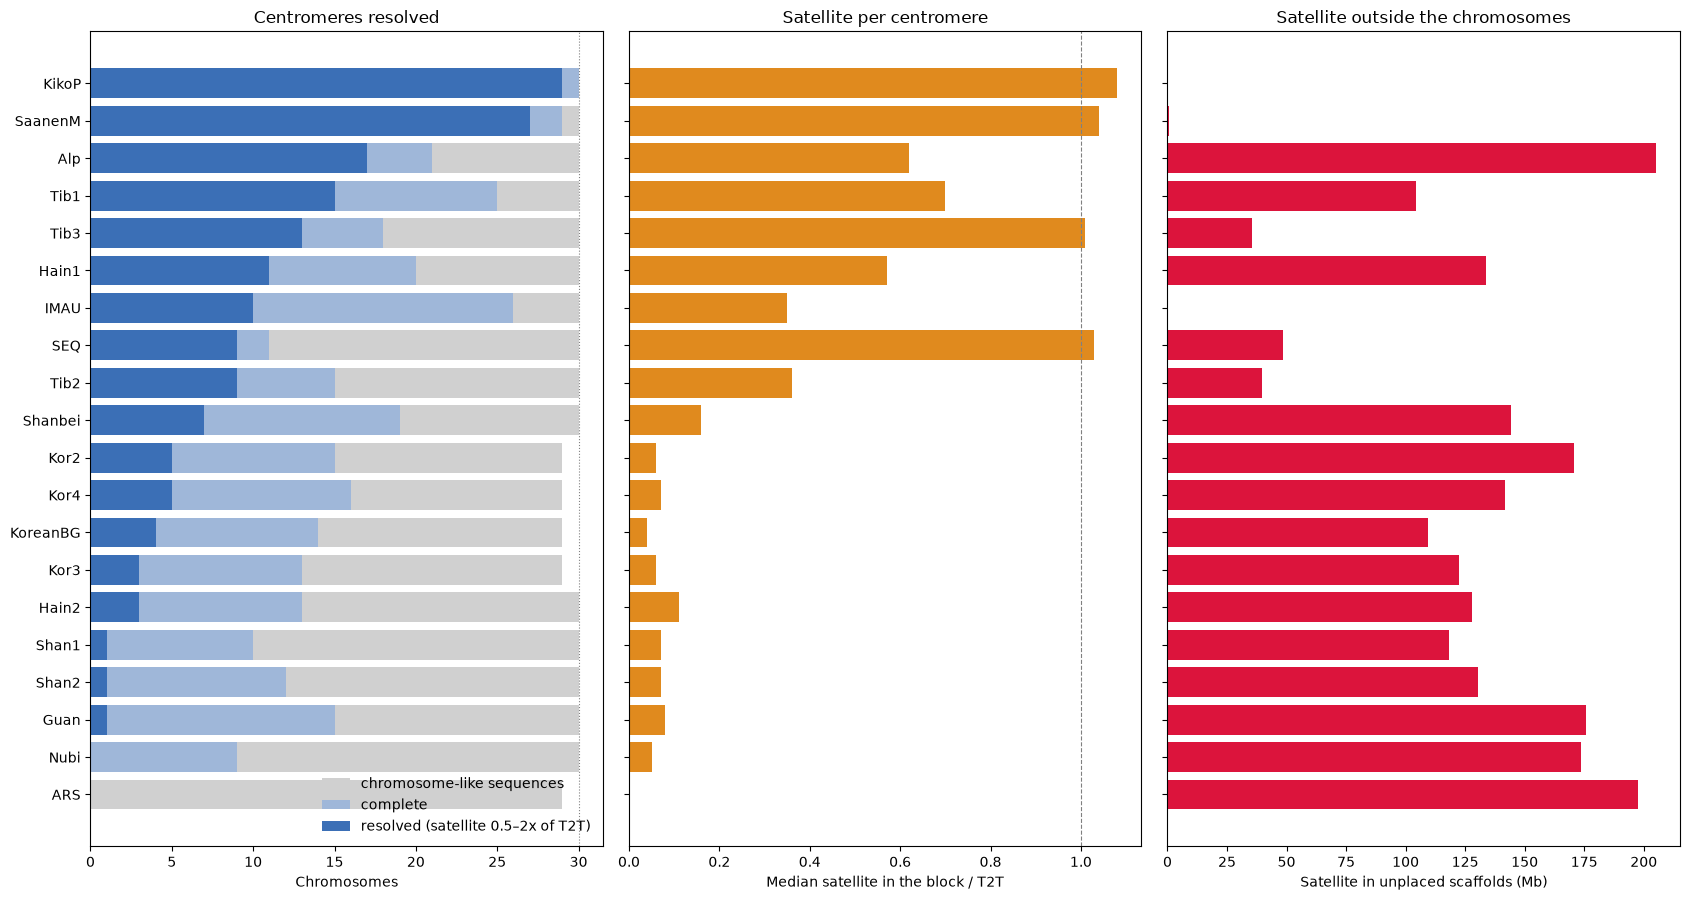

In [5]:
d = s.drop(index='T2T (ref)', errors='ignore').dropna(subset=['complete']).sort_values('resolved'); y = np.arange(len(d))
fig, ax = plt.subplots(1, 3, figsize=(17, max(4, .38*len(d) + 1.5)), sharey=True)
ax[0].barh(y, d.chromosome_like_sequences, color='#d0d0d0', label='chromosome-like sequences'); ax[0].barh(y, d.complete, color='#9fb7d9', label='complete'); ax[0].barh(y, d.resolved, color='#3b6fb6', label='resolved (satellite 0.5–2x of T2T)'); ax[0].set_yticks(y); ax[0].set_yticklabels(d.index)
ax[0].axvline(30, color='gray', ls=':', lw=.8); ax[0].set_xlabel('Chromosomes'); ax[0].legend(frameon=False, loc='lower right'); ax[0].set_title('Centromeres resolved')
ax[1].barh(y, d.median_sat_vs_T2T, color='#e08a1e'); ax[1].axvline(1, color='gray', ls='--', lw=.8); ax[1].set_xlabel('Median satellite in the block / T2T'); ax[1].set_title('Satellite per centromere')
ax[2].barh(y, d.unplaced_satellite_Mb, color='crimson'); ax[2].set_xlabel('Satellite in unplaced scaffolds (Mb)'); ax[2].set_title('Satellite outside the chromosomes')
plt.tight_layout(); plt.savefig(FIG/'screen_overview.png', dpi=150); plt.show()